In [58]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("mnist_train.csv")
test_df = pd.read_csv("mnist_test.csv")

display(train_df.head())
display(test_df.head())
# CSV files should be in the same folder as this notebook.
#TRAIN_CSV = Path("mnist_train.csv")
#TEST_CSV = Path("mnist_test.csv")

#print("Training file:", TRAIN_CSV.resolve())
#print("Test file:", TEST_CSV.resolve())

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [59]:

#train_df = pd.read_csv(mnist_train)
#test_df = pd.read_csv(mnist_test)

print("Training DataFrame shape:", train_df.shape)
print("Test DataFrame shape:", test_df.shape)
display(train_df.head())

Training DataFrame shape: (60000, 785)
Test DataFrame shape: (10000, 785)


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [60]:
# 3. Validate the DataFrames and convert them to NumPy arrays
EXPECTED_COLUMNS = 785
if train_df.shape[1] != EXPECTED_COLUMNS:
    raise ValueError(f"Training CSV must have 785 columns (label + 784 pixels); found {train_df.shape[1]}.")
if test_df.shape[1] != EXPECTED_COLUMNS:
    raise ValueError(f"Test CSV must have 785 columns (label + 784 pixels); found {test_df.shape[1]}.")

train_array = train_df.to_numpy()
test_array = test_df.to_numpy()
y_train = train_array[:, 0].astype(np.int64)
X_train = train_array[:, 1:].astype(np.float32)
y_test = test_array[:, 0].astype(np.int64)
X_test = test_array[:, 1:].astype(np.float32)

if not np.isin(y_train, np.arange(10)).all() or not np.isin(y_test, np.arange(10)).all():
    raise ValueError("Labels must be integers from 0 through 9.")
if not np.isfinite(X_train).all() or not np.isfinite(X_test).all():
    raise ValueError("Pixel data contains missing or non-numeric values.")

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)


X_train: (60000, 784) y_train: (60000,)
X_test: (10000, 784) y_test: (10000,)


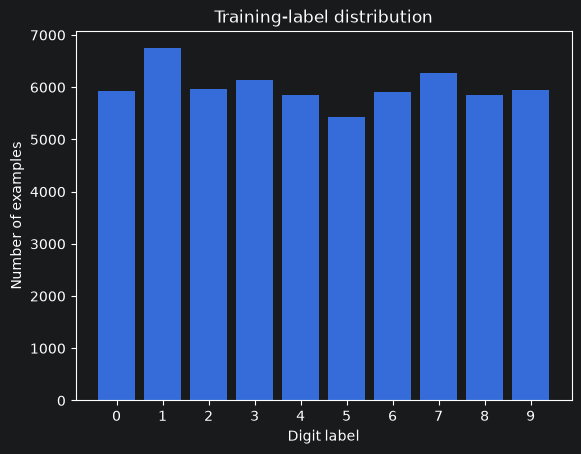

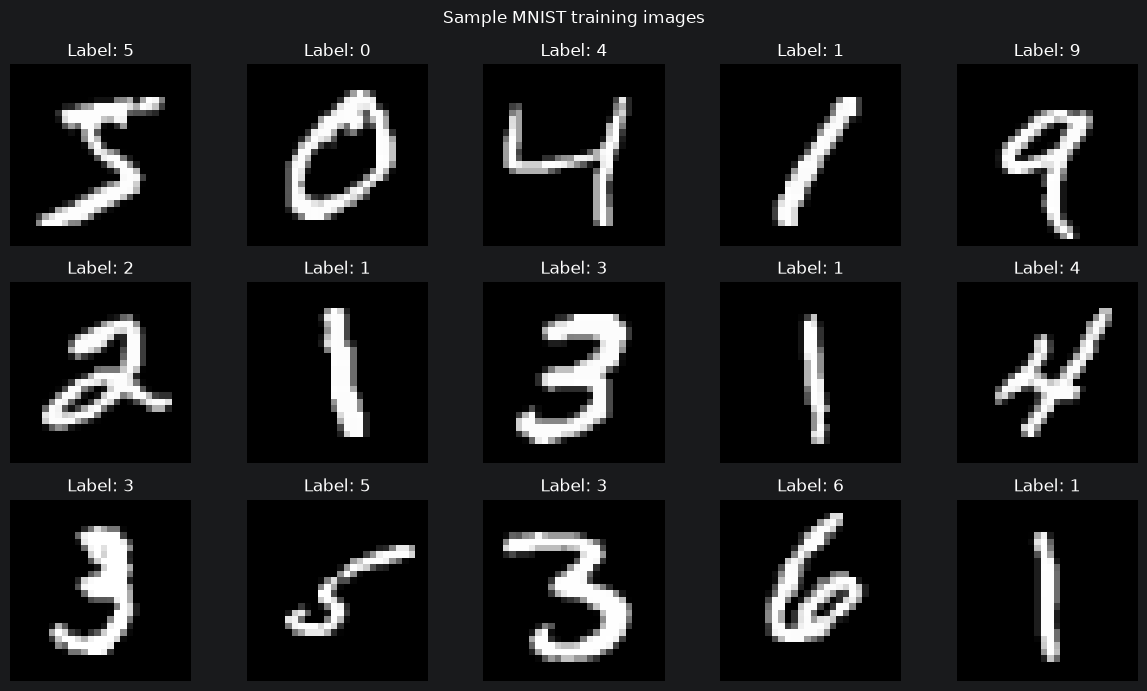

In [61]:
classes, counts = np.unique(y_train, return_counts=True)
plt.bar(classes, counts)
plt.xlabel("Digit label"); plt.ylabel("Number of examples")
plt.title("Training-label distribution"); plt.xticks(range(10))
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST training images")
plt.tight_layout()
plt.show()

Pixel range: 0.0 to 1.0


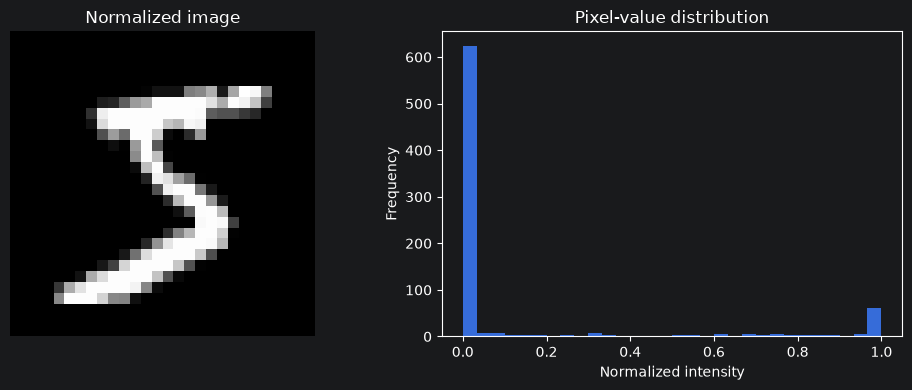

In [62]:
X_train = X_train / 255.0
X_test = X_test / 255.0
print("Pixel range:", X_train.min(), "to", X_train.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(X_train[0].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Normalized image"); axes[0].axis("off")
axes[1].hist(X_train[0], bins=30)
axes[1].set_title("Pixel-value distribution")
axes[1].set_xlabel("Normalized intensity"); axes[1].set_ylabel("Frequency")
plt.tight_layout(); plt.show()

Label: 5 One-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


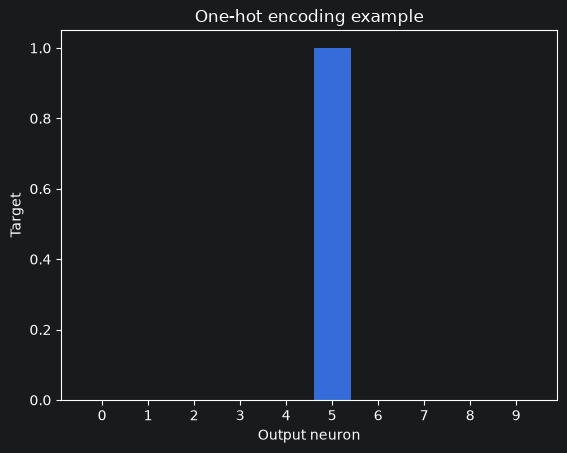

In [63]:
def one_hot_encode(y, num_classes=10):
    result = np.zeros((len(y), num_classes), dtype=np.float32)
    result[np.arange(len(y)), y] = 1.0
    return result

Y_train = one_hot_encode(y_train)
Y_test = one_hot_encode(y_test)
print("Label:", y_train[0], "One-hot:", Y_train[0])

plt.bar(range(10), Y_train[0])
plt.xlabel("Output neuron"); plt.ylabel("Target")
plt.title("One-hot encoding example"); plt.xticks(range(10)); plt.show()

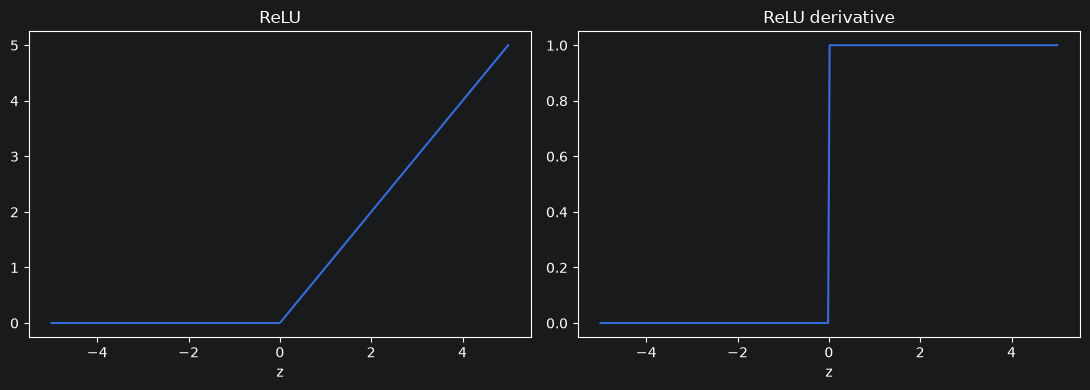

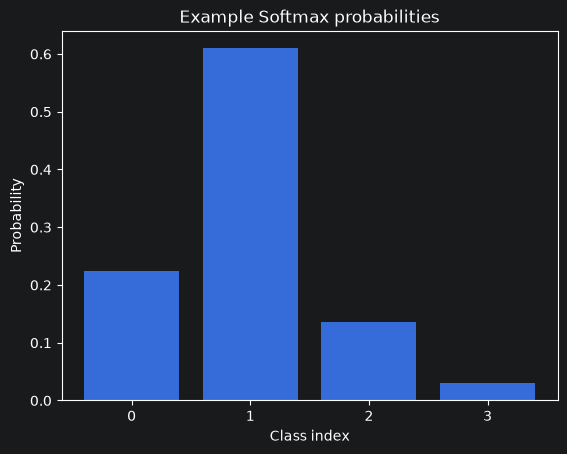

Probabilities: [0.22420782 0.60946004 0.13598892 0.03034323]
Sum of probabilities: 0.9999999999999999


In [64]:
def relu(z):
    return np.maximum(0.0, z)

def relu_derivative(z):
    return (z > 0).astype(np.float32)

def softmax(z):
    # Subtract row maximum for numerical stability
    shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

z = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(z, relu(z)); axes[0].set_title("ReLU"); axes[0].set_xlabel("z")
axes[1].plot(z, relu_derivative(z)); axes[1].set_title("ReLU derivative"); axes[1].set_xlabel("z")
plt.tight_layout(); plt.show()

example_logits = np.array([[1.0, 2.0, 0.5, -1.0]])
example_probs = softmax(example_logits)[0]
plt.bar(range(len(example_probs)), example_probs)
plt.title("Example Softmax probabilities"); plt.xlabel("Class index"); plt.ylabel("Probability")
plt.xticks(range(len(example_probs))); plt.show()
print("Probabilities:", example_probs)
print("Sum of probabilities:", example_probs.sum())


W1: (784, 128) std: 0.010008096
b1: (1, 128) W2: (128, 10) std: 0.009693272 b2: (1, 10)


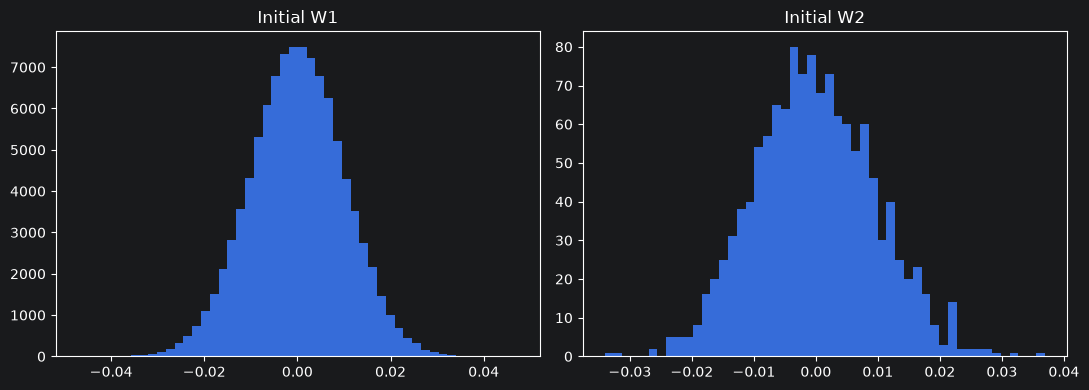

In [65]:
INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE = 784, 128, 10
STD_DEV = 0.01

def initialize_parameters(input_size, hidden_size, output_size, std_dev):
    W1 = np.random.normal(0, std_dev, (input_size, hidden_size)).astype(np.float32)
    b1 = np.zeros((1, hidden_size), dtype=np.float32)
    W2 = np.random.normal(0, std_dev, (hidden_size, output_size)).astype(np.float32)
    b2 = np.zeros((1, output_size), dtype=np.float32)
    return W1, b1, W2, b2

W1, b1, W2, b2 = initialize_parameters(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, STD_DEV)
print("W1:", W1.shape, "std:", np.std(W1))
print("b1:", b1.shape, "W2:", W2.shape, "std:", np.std(W2), "b2:", b2.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(W1.ravel(), bins=50); axes[0].set_title("Initial W1")
axes[1].hist(W2.ravel(), bins=50); axes[1].set_title("Initial W2")
plt.tight_layout(); plt.show()

X (5, 784)
Z1 (5, 128)
A1 (5, 128)
Z2 (5, 10)
A2 (5, 10)
First example probability sum: 1.0
 probability sum: [[0.09855339 0.10029558 0.10051972 0.10020801 0.1011249  0.10004674
  0.09825561 0.10064325 0.09964087 0.10071196]
 [0.09959339 0.10111966 0.09997477 0.10020848 0.10087167 0.09893116
  0.09855128 0.10083047 0.10000867 0.09991042]
 [0.09985711 0.10034189 0.09994718 0.09907804 0.10017087 0.10042179
  0.09978532 0.09960532 0.10006014 0.1007323 ]
 [0.09857462 0.09969014 0.1010233  0.09981261 0.10032073 0.10025973
  0.1002476  0.10022814 0.09990902 0.09993412]
 [0.09939307 0.09967878 0.10050891 0.10068689 0.10115649 0.09938321
  0.09949938 0.0995627  0.10014359 0.09998696]]


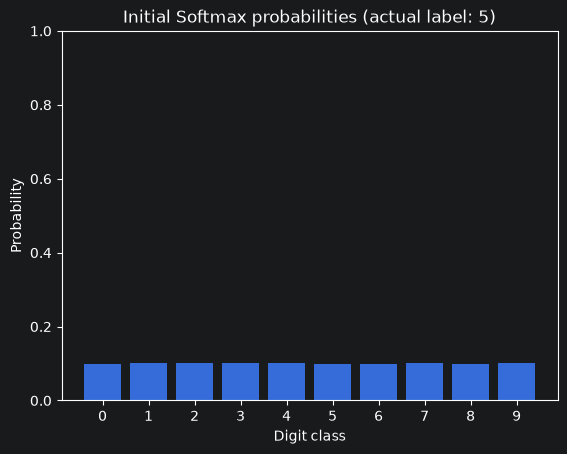

In [66]:
def forward_propagation(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)
    cache = {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache
# z1 calculate the ReLU derivative a1 Calculate gradients for W2 z2 output calc  a2Calculate output-layer error
initial_probabilities, cache = forward_propagation(X_train[:5], W1, b1, W2, b2)
for key, value in cache.items():
    print(key, value.shape)
print("First example probability sum:", initial_probabilities[0].sum())
print(" probability sum:", initial_probabilities)
plt.bar(range(10), initial_probabilities[0])
plt.xlabel("Digit class"); plt.ylabel("Probability")
plt.title(f"Initial Softmax probabilities (actual label: {y_train[0]})")
plt.xticks(range(10)); plt.ylim(0, 1); plt.show()


Initial cross-entropy loss: 2.3036118
Initial cross-entropy loss: 2.3036118


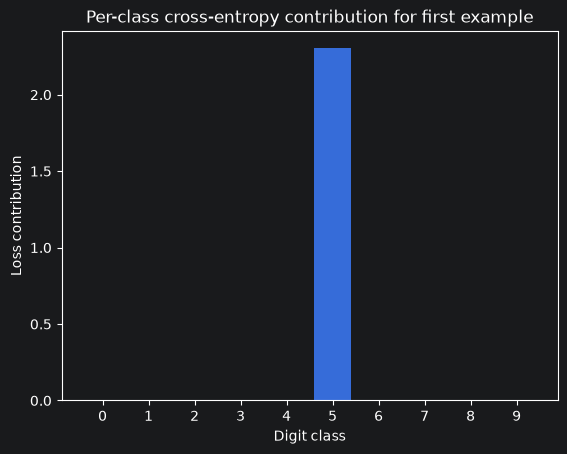

In [67]:
def cross_entropy_loss(Y_true, probabilities):
    eps = 1e-12
    probabilities = np.clip(probabilities, eps, 1.0 - eps)
    return -np.mean(np.sum(Y_true * np.log(probabilities), axis=1))

print("Initial cross-entropy loss:", cross_entropy_loss(Y_train[:5], initial_probabilities))
print("Initial cross-entropy loss:", cross_entropy_loss(Y_train[:5], initial_probabilities))
class_loss = -Y_train[0] * np.log(np.clip(initial_probabilities[0], 1e-12, 1.0))
plt.bar(range(10), class_loss)
plt.xlabel("Digit class"); plt.ylabel("Loss contribution")
plt.title("Per-class cross-entropy contribution for first example")
plt.xticks(range(10)); plt.show()


dW1 (784, 128) gradient norm: 0.13780473
db1 (1, 128) gradient norm: 0.012086704
dW2 (128, 10) gradient norm: 0.13518761
db2 (1, 10) gradient norm: 0.13782972


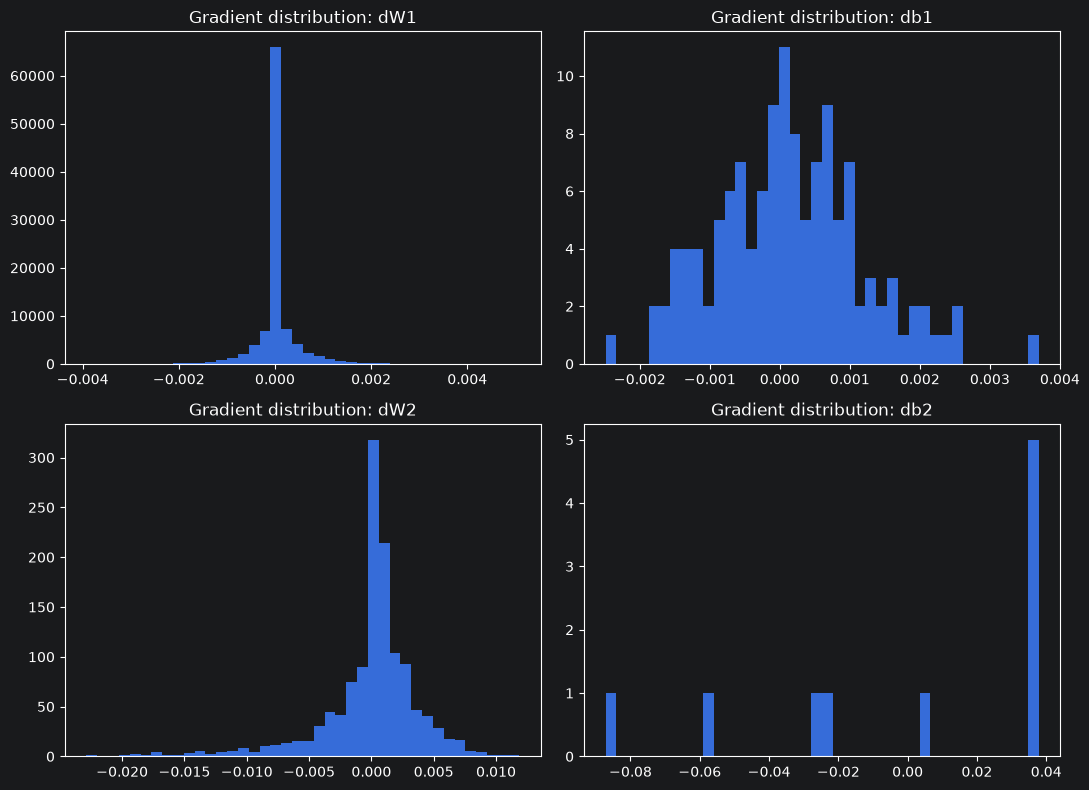

In [68]:
def backpropagation(Y_true, cache, W2):
    X, Z1, A1 = cache["X"], cache["Z1"], cache["A1"]
    A2 = cache["A2"]
    m = X.shape[0]

    # Softmax + cross-entropy gradient
    dZ2 = (A2 - Y_true) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Backpropagate through W2 and hidden ReLU
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}

probabilities, small_cache = forward_propagation(X_train[:32], W1, b1, W2, b2)
gradients = backpropagation(Y_train[:32], small_cache, W2)
for name, value in gradients.items():
    print(name, value.shape, "gradient norm:", np.linalg.norm(value))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axes.flat, ["dW1", "db1", "dW2", "db2"]):
    ax.hist(gradients[name].ravel(), bins=40)
    ax.set_title(f"Gradient distribution: {name}")
plt.tight_layout(); plt.show()


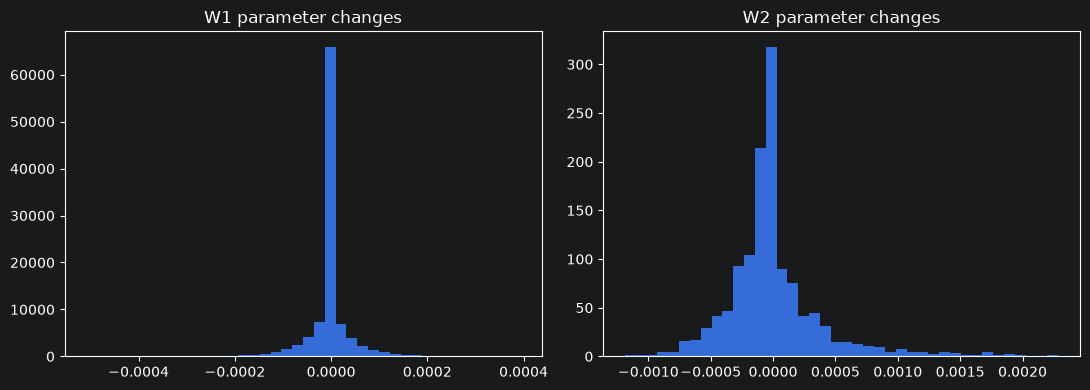

In [69]:
def update_parameters(W1, b1, W2, b2, gradients, learning_rate):
    W1 = W1 - learning_rate * gradients["dW1"]
    b1 = b1 - learning_rate * gradients["db1"]
    W2 = W2 - learning_rate * gradients["dW2"]
    b2 = b2 - learning_rate * gradients["db2"]
    return W1, b1, W2, b2

W1_before, W2_before = W1.copy(), W2.copy()
W1_demo, b1_demo, W2_demo, b2_demo = update_parameters(W1, b1, W2, b2, gradients, 0.1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist((W1_demo - W1_before).ravel(), bins=40); axes[0].set_title("W1 parameter changes")
axes[1].hist((W2_demo - W2_before).ravel(), bins=40); axes[1].set_title("W2 parameter changes")
plt.tight_layout(); plt.show()

In [70]:
# Fresh initialization for the actual training run
W1, b1, W2, b2 = initialize_parameters(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, STD_DEV)

EPOCHS = 25
BATCH_SIZE = 128
LEARNING_RATE = 0.1
history = {"loss": [], "train_accuracy": [], "test_accuracy": []}
n_train = len(X_train)

for epoch in range(EPOCHS):
    order = np.random.permutation(n_train)
    X_shuffled, Y_shuffled = X_train[order], Y_train[order]

    for start in range(0, n_train, BATCH_SIZE):
        end = min(start + BATCH_SIZE, n_train)
        X_batch, Y_batch = X_shuffled[start:end], Y_shuffled[start:end]
        batch_probabilities, batch_cache = forward_propagation(X_batch, W1, b1, W2, b2)
        batch_gradients = backpropagation(Y_batch, batch_cache, W2)
        W1, b1, W2, b2 = update_parameters(
            W1, b1, W2, b2, batch_gradients, LEARNING_RATE
        )

    train_probabilities, _ = forward_propagation(X_train, W1, b1, W2, b2)
    test_probabilities, _ = forward_propagation(X_test, W1, b1, W2, b2)
    train_loss = cross_entropy_loss(Y_train, train_probabilities)
    train_pred = np.argmax(train_probabilities, axis=1)
    test_pred = np.argmax(test_probabilities, axis=1)
    train_acc = np.mean(train_pred == y_train)
    test_acc = np.mean(test_pred == y_test)

    history["loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["test_accuracy"].append(test_acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | Cross-entropy={train_loss:.5f} | train={train_acc:.4f} | test={test_acc:.4f}")


Epoch 1/25 | Cross-entropy=0.35342 | train=0.8990 | test=0.9040
Epoch 2/25 | Cross-entropy=0.27714 | train=0.9216 | test=0.9256
Epoch 3/25 | Cross-entropy=0.23511 | train=0.9332 | test=0.9356
Epoch 4/25 | Cross-entropy=0.19895 | train=0.9441 | test=0.9432
Epoch 5/25 | Cross-entropy=0.18188 | train=0.9485 | test=0.9473
Epoch 6/25 | Cross-entropy=0.15629 | train=0.9560 | test=0.9547
Epoch 7/25 | Cross-entropy=0.13720 | train=0.9619 | test=0.9586
Epoch 8/25 | Cross-entropy=0.12693 | train=0.9640 | test=0.9616
Epoch 9/25 | Cross-entropy=0.11598 | train=0.9674 | test=0.9647
Epoch 10/25 | Cross-entropy=0.10521 | train=0.9705 | test=0.9669
Epoch 11/25 | Cross-entropy=0.09780 | train=0.9728 | test=0.9689
Epoch 12/25 | Cross-entropy=0.09419 | train=0.9741 | test=0.9692
Epoch 13/25 | Cross-entropy=0.08511 | train=0.9768 | test=0.9701
Epoch 14/25 | Cross-entropy=0.07795 | train=0.9786 | test=0.9729
Epoch 15/25 | Cross-entropy=0.07425 | train=0.9795 | test=0.9737
Epoch 16/25 | Cross-entropy=0.0707

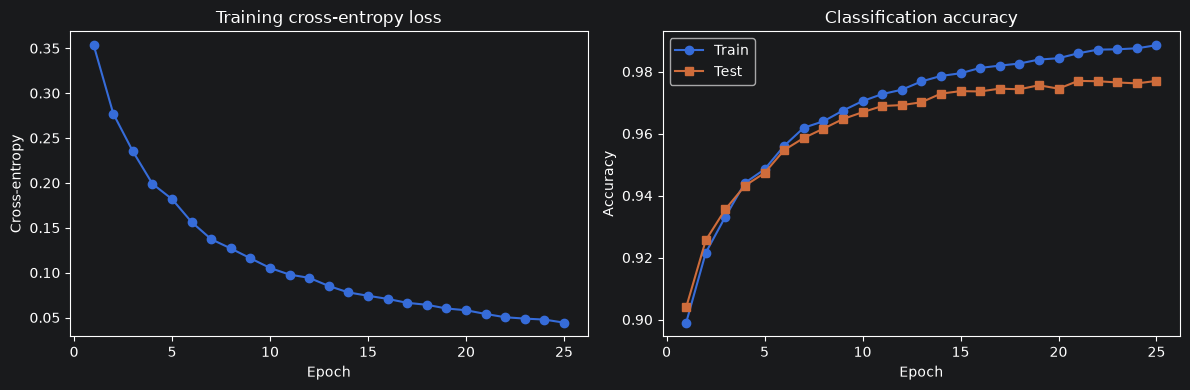

In [71]:
ep = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, history["loss"], marker="o")
axes[0].set_title("Training cross-entropy loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy")
axes[1].plot(ep, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(ep, history["test_accuracy"], marker="s", label="Test")
axes[1].set_title("Classification accuracy"); axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()


Test cross-entropy: 0.07323
Test accuracy: 97.70%
Correct: 9770 / 10000


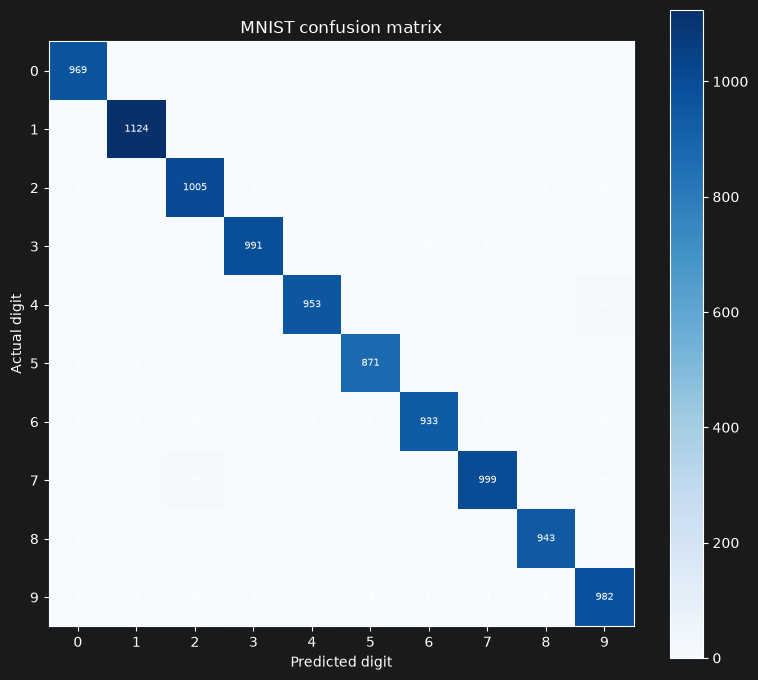

In [72]:
test_probabilities, _ = forward_propagation(X_test, W1, b1, W2, b2)
y_pred = np.argmax(test_probabilities, axis=1)
print(f"Test cross-entropy: {cross_entropy_loss(Y_test, test_probabilities):.5f}")
print(f"Test accuracy: {np.mean(y_pred == y_test) * 100:.2f}%")
print(f"Correct: {np.sum(y_pred == y_test)} / {len(y_test)}")

confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (y_test, y_pred), 1)
plt.figure(figsize=(8, 7))
plt.imshow(confusion, cmap="Blues"); plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Predicted digit"); plt.ylabel("Actual digit")
plt.title("MNIST confusion matrix")
for i in range(10):
    for j in range(10):
        plt.text(j, i, str(confusion[i, j]), ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.show()


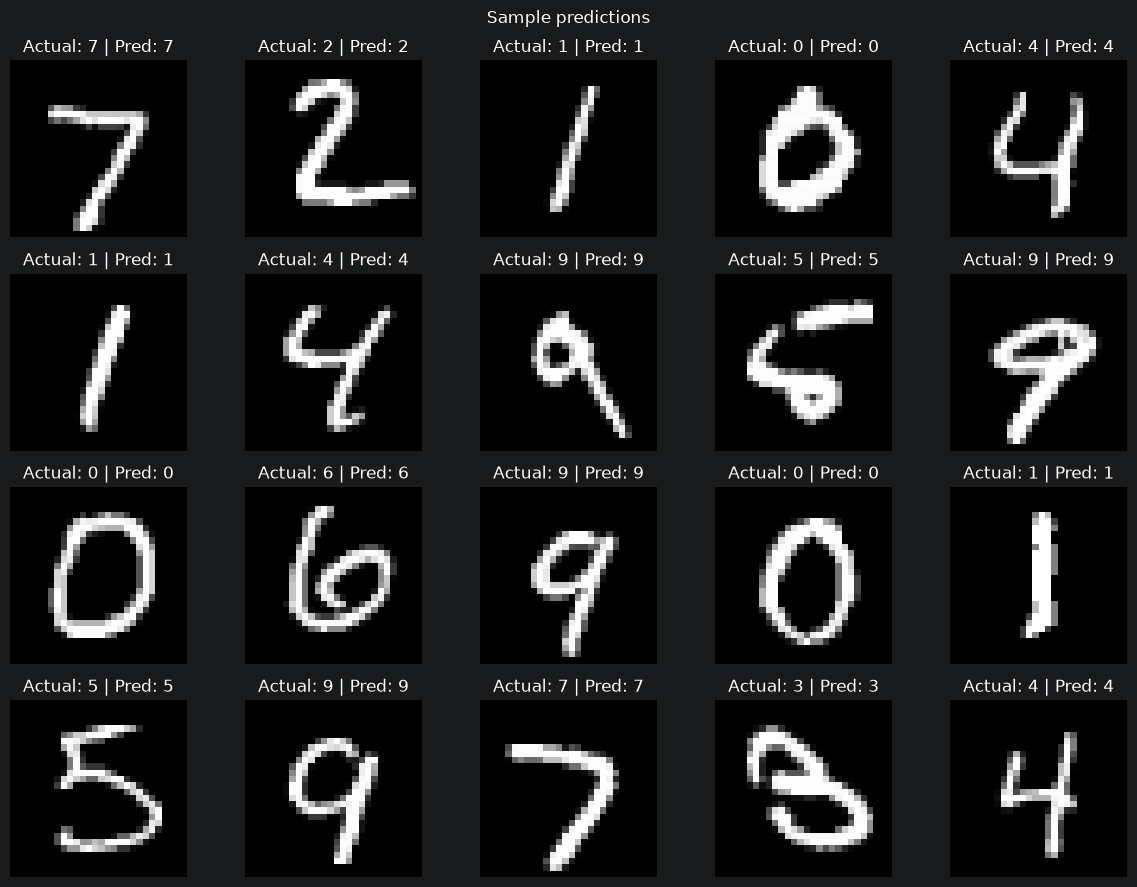

Misclassified images: 230


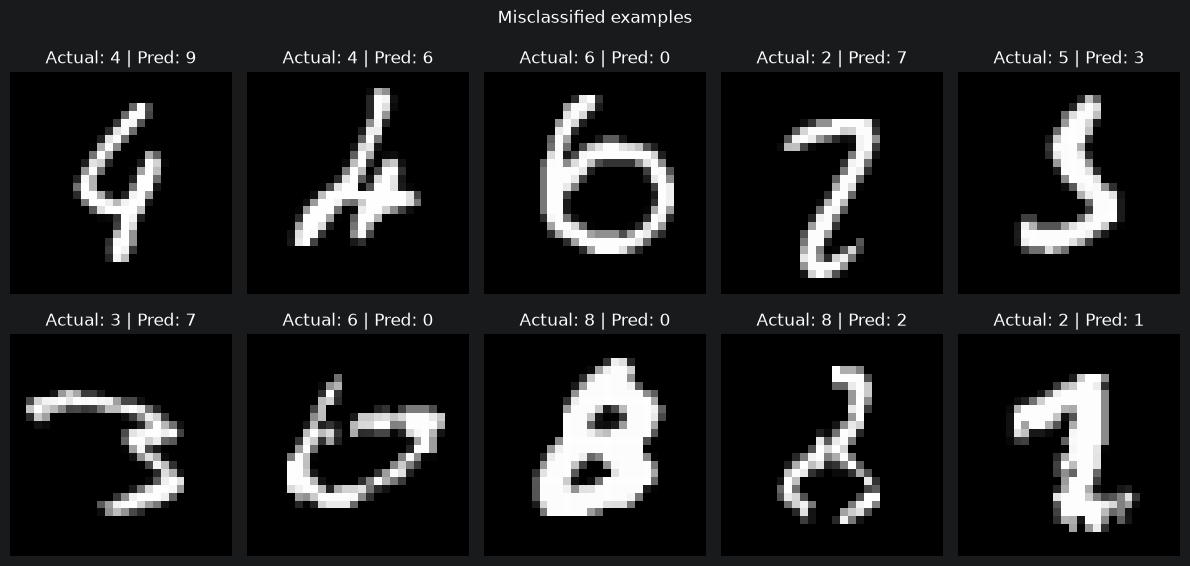

In [73]:
fig, axes = plt.subplots(4, 5, figsize=(12, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Actual: {y_test[i]} | Pred: {y_pred[i]}")
    ax.axis("off")
plt.suptitle("Sample predictions"); plt.tight_layout(); plt.show()

wrong = np.flatnonzero(y_pred != y_test)
print("Misclassified images:", len(wrong))
if len(wrong):
    n = min(10, len(wrong))
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    for ax, idx in zip(axes.flat, wrong[:n]):
        ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
        ax.set_title(f"Actual: {y_test[idx]} | Pred: {y_pred[idx]}")
        ax.axis("off")
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.suptitle("Misclassified examples"); plt.tight_layout(); plt.show()

In [ ]:
def gradient_check():
    rng = np.random.default_rng(7)
    X = rng.random((3, 4))
    Y = one_hot_encode(np.array([0, 1, 2]), 3).astype(np.float64)
    W1c = rng.normal(0, 0.1, (4, 5))
    b1c = np.zeros((1, 5))
    W2c = rng.normal(0, 0.1, (5, 3))
    b2c = np.zeros((1, 3))

    _, cache_c = forward_propagation(X, W1c, b1c, W2c, b2c)
    analytical = backpropagation(Y, cache_c, W2c)
    params = [("W1", W1c, "dW1"), ("b1", b1c, "db1"),
              ("W2", W2c, "dW2"), ("b2", b2c, "db2")]
    eps = 1e-5

    for name, param, grad_name in params:
        idx = (0, 0)
        original = param[idx]
        param[idx] = original + eps
        p_plus, _ = forward_propagation(X, W1c, b1c, W2c, b2c)
        loss_plus = cross_entropy_loss(Y, p_plus)
        param[idx] = original - eps
        p_minus, _ = forward_propagation(X, W1c, b1c, W2c, b2c)
        loss_minus = cross_entropy_loss(Y, p_minus)
        param[idx] = original

        numeric = (loss_plus - loss_minus) / (2 * eps)
        analytic = analytical[grad_name][idx]
        rel = abs(numeric - analytic) / (abs(numeric) + abs(analytic) + 1e-12)
        print(f"{name}: numerical={numeric:.8e}, analytical={analytic:.8e}, relative error={rel:.3e}")

gradient_check()